# Can a single neuron tell time?

Timing in the brain spans six orders of magnitude. A barn owl locates a mouse by sound arrival
differences of a few microseconds. A person reproduces an interval of a second. A typical neuron
forgets its input within some tens of milliseconds. Which of these timing problems can one neuron
solve on its own, and which need more?

**Part I · Foundations** builds the standard model neuron from its equation: integration, threshold,
noise, spike statistics, and the difference between an integrator and a coincidence detector.

**Part II · Case study** asks the timing question in six stages:

| stage | question |
|---|---|
| 1. Cognitive phenomenon | What needs explaining? |
| 2. Behavioral experiment | How do we make it measurable? |
| 3. Empirical signature | What pattern in the data is the phenomenon? |
| 4. Computational model | What computation produces it, and can we identify it? |
| 5. Neural implementation | Could neurons carry it out? |
| 6. Prediction and failure | Which result would prove the model wrong? |

All neurons here are simulated, so every estimate can be checked against the truth.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import curve_fit

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
rng = np.random.default_rng(0)

# Part I · Foundations

## 1. The leaky integrate-and-fire neuron

A neuron's membrane is a leaky bucket of charge. Input current fills it; a leak drains it back to
rest. When the voltage reaches a threshold, the neuron fires a spike and the voltage is reset. This
is the leaky integrate-and-fire (LIF) model, which goes back to Lapicque (1907).

$$\tau \frac{d\mu}{dt} = -(\mu - \mu_0) + R\,I(t), \qquad \text{spike and reset when } \mu \ge \theta.$$

| symbol | meaning | value here |
|---|---|---|
| $\mu$ | membrane potential: how charged the bucket is | mV |
| $\mu_0$ | resting potential: where the leak pulls the voltage | $-70$ mV |
| $I(t)$ | input current from synapses or an electrode | nA |
| $R$ | membrane resistance: how much voltage one unit of current produces | 10 M$\Omega$ |
| $\tau = RC$ | membrane time constant: how long the bucket remembers | 20 ms |
| $\theta$ | spike threshold | $-54$ mV |

The time constant $\tau$ is the central quantity of this tutorial. It is the neuron's memory span.

### Euler steps

A computer advances the equation in small steps of size $\Delta t$:

$$\mu_{t+1} = \mu_t + \frac{\Delta t}{\tau}\big(-(\mu_t - \mu_0) + R\,I_t\big).$$

For a constant input there is also a closed form, which lets us check the steps:
$\mu(t) = \mu_\infty + (\mu_0 - \mu_\infty)e^{-t/\tau}$ with $\mu_\infty = \mu_0 + RI$.

largest difference Euler vs closed form: 0.070 mV


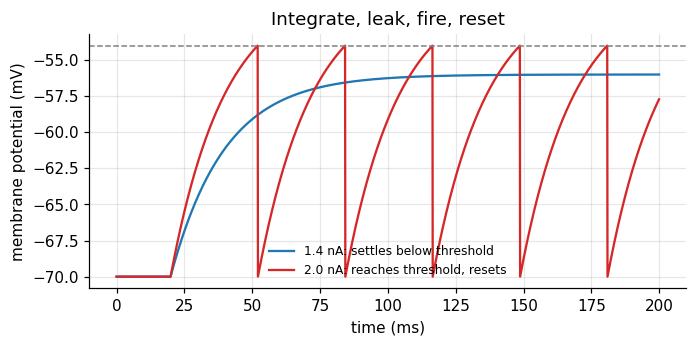

In [2]:
tau, R, mu0, theta, mu_reset = 20.0, 10.0, -70.0, -54.0, -70.0   # ms, MOhm, mV, mV, mV
dt = 0.1                                                         # ms
t = np.arange(0, 200, dt)                                        # (T,) time axis


def lif(I, tau=tau, noise=0.0, rng=rng, spikes=True):
    # I: (n, T) input currents for n neurons or trials. Returns voltage (n, T) and spike mask (n, T).
    I = np.atleast_2d(I)
    n, T = I.shape
    mu = np.full(n, mu0)
    V = np.empty((n, T)); S = np.zeros((n, T), bool)
    for k in range(T):
        mu = mu + dt / tau * (-(mu - mu0) + R * I[:, k]) + noise * np.sqrt(dt) * rng.normal(size=n)
        if spikes:
            fired = mu >= theta
            S[fired, k] = True
            mu[fired] = mu_reset
        V[:, k] = mu
    return V, S


I_step = np.where(t >= 20, 1.4, 0.0)                              # (T,) step of 1.4 nA, below threshold
V, _ = lif(I_step, spikes=False)                                  # (1, T)
closed = np.where(t >= 20, mu0 + R * 1.4 * (1 - np.exp(-(t - 20) / tau)), mu0)
print(f"largest difference Euler vs closed form: {np.abs(V[0] - closed).max():.3f} mV")

I_supra = np.where(t >= 20, 2.0, 0.0)                             # 2.0 nA, above threshold
V2, S2 = lif(I_supra)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(t, V[0], color="C0", label="1.4 nA: settles below threshold")
ax.plot(t, V2[0], color="C3", label="2.0 nA: reaches threshold, resets")
ax.axhline(theta, color="0.5", ls="--", lw=1)
ax.set(xlabel="time (ms)", ylabel="membrane potential (mV)", title="Integrate, leak, fire, reset")
ax.legend(frameon=False, fontsize=8)
plt.show()

## 2. From input to firing rate: the f-I curve

With a constant input above threshold, the neuron fires regularly. The time from reset to threshold
follows from the closed form. Solving $\mu(T) = \theta$ gives the interspike interval, and its
inverse is the rate:

$$f(I) = \left[t_\text{ref} + \tau \ln \frac{RI}{RI - (\theta - \mu_0)}\right]^{-1} \quad \text{for } RI > \theta - \mu_0, \text{ else } 0.$$

Here $t_\text{ref}$ is a refractory period after each spike; our simulation has none, so
$t_\text{ref} = 0$. Below the threshold current $(\theta - \mu_0)/R = 1.6$ nA the rate is exactly zero.

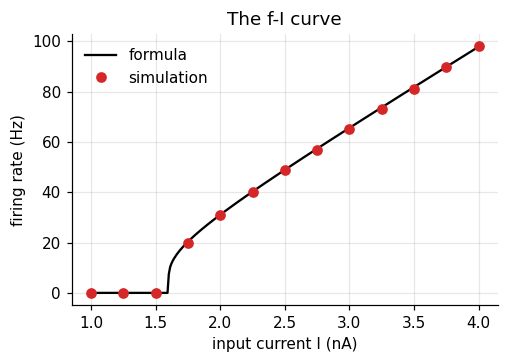

In [3]:
I_levels = np.linspace(1.0, 4.0, 13)                              # (L,) constant input levels
t_long = np.arange(0, 1000, dt)                                   # 1 s of simulation
_, S = lif(np.repeat(I_levels[:, None], t_long.size, axis=1))     # (L, T) spikes
rate_sim = S.sum(axis=1) / 1.0                                    # (L,) spikes per second

I_fine = np.linspace(1.0, 4.0, 300)
drive = R * I_fine
rate_formula = np.where(drive > theta - mu0,
                        1000 / (tau * np.log(drive / np.maximum(drive - (theta - mu0), 1e-9))), 0)

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(I_fine, rate_formula, color="k", label="formula")
ax.plot(I_levels, rate_sim, "o", color="C3", label="simulation")
ax.set(xlabel="input current I (nA)", ylabel="firing rate (Hz)", title="The f-I curve")
ax.legend(frameon=False)
plt.show()

The curve has a hard threshold and then rises roughly linearly. That shape, zero then rising, is the
"nonlinearity" that appears in almost every rate model.

## 3. The neuron as a linear filter

Below threshold the LIF equation is linear. Then the voltage is the input convolved with a fixed
kernel:

$$\mu(t) - \mu_0 = \int_0^\infty k(u)\, I(t-u)\, du, \qquad k(u) = \frac{R}{\tau} e^{-u/\tau}.$$

The kernel says how much an input $u$ milliseconds ago still counts now. It halves every
$\tau \ln 2 \approx 14$ ms. In code the convolution is `np.convolve(I, k)[:T] * dt`, shape (T,).

largest difference Euler vs convolution: 0.027 mV


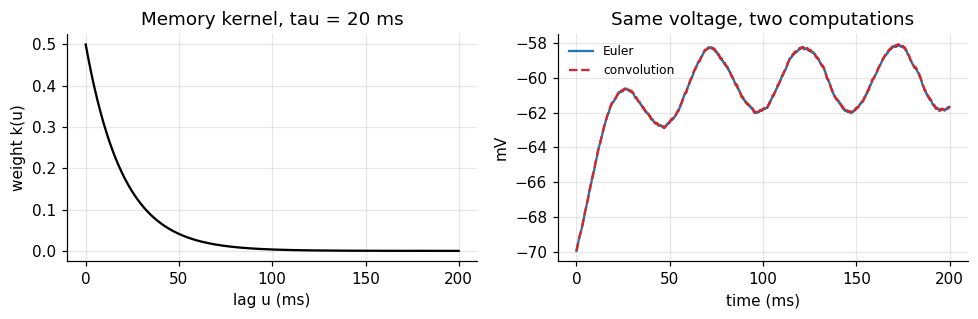

In [4]:
I_wiggle = 1.0 + 0.5 * np.sin(2 * np.pi * t / 50) + 0.3 * rng.normal(size=t.size)   # (T,) arbitrary input
V_euler, _ = lif(I_wiggle, spikes=False)                          # (1, T)
k = (R / tau) * np.exp(-t / tau)                                  # (T,) the kernel
V_conv = mu0 + np.convolve(I_wiggle, k)[: t.size] * dt            # (T,)
print(f"largest difference Euler vs convolution: {np.abs(V_euler[0] - V_conv).max():.3f} mV")

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(t, k, color="k")
axes[0].set(xlabel="lag u (ms)", ylabel="weight k(u)", title="Memory kernel, tau = 20 ms")
axes[1].plot(t, V_euler[0], color="C0", label="Euler")
axes[1].plot(t, V_conv, color="C3", ls="--", label="convolution")
axes[1].set(xlabel="time (ms)", ylabel="mV", title="Same voltage, two computations")
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

The small difference comes from the Euler step, not from the theory. This view matters for timing:
whatever the neuron "knows" about the past is a weighted sum with weights that decay as
$e^{-u/\tau}$. After a few $\tau$, the past is gone.

## 4. Noise and reliability

Real neurons are noisy. Add a fluctuating term to the equation and ask a simple question: if the
same input is given twice, do the spikes come at the same times? Mainen and Sejnowski (1995) did
this in cortical slices. With a constant current the spike times drifted apart across repeats.
With a fluctuating current, repeated identically ("frozen noise"), the spikes lined up.

We repeat their logic. Both inputs have the same mean. Each repeat adds fresh internal noise.

constant             spikes per repeat 20.3, reliability 0.02
frozen fluctuating   spikes per repeat 25.1, reliability 0.54


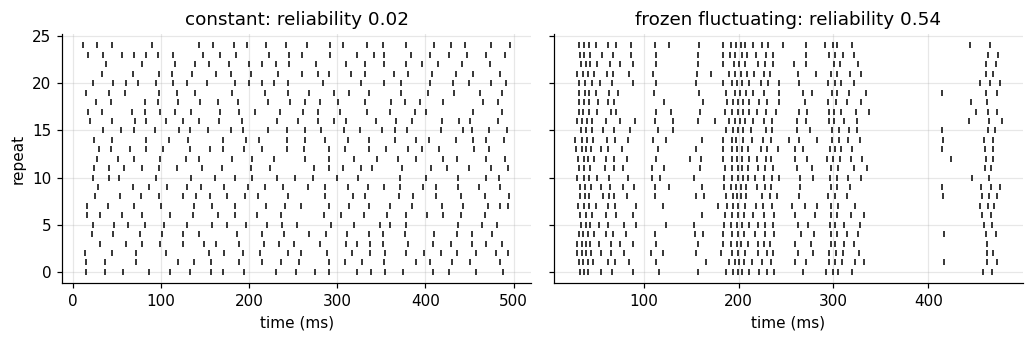

In [5]:
n_rep = 25
t_rel = np.arange(0, 500, dt)
z = gaussian_filter1d(rng.normal(size=t_rel.size), 5 / dt)       # (T,) noise smoothed over about 5 ms
frozen = 2.2 + 2.0 * z / z.std()                                  # (T,) same mean as the constant input
inputs = {"constant": np.full(t_rel.size, 2.2), "frozen fluctuating": frozen}


def reliability(S, smooth_ms=2.0):
    # Mean correlation between repeats after smoothing each spike train: 0 = unrelated, 1 = identical
    g = gaussian_filter1d(S.astype(float), smooth_ms / dt, axis=1)   # (n_rep, T)
    g -= g.mean(axis=1, keepdims=True)
    g /= np.linalg.norm(g, axis=1, keepdims=True)
    C = g @ g.T                                                   # (n_rep, n_rep)
    return (C.sum() - n_rep) / (n_rep ** 2 - n_rep)


fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.2), sharey=True)
for ax, (name, I) in zip(axes, inputs.items()):
    _, S = lif(np.tile(I, (n_rep, 1)), noise=1.0)                 # (n_rep, T) fresh internal noise each repeat
    for r in range(n_rep):
        ax.plot(t_rel[S[r]], np.full(S[r].sum(), r), "|", color="k", ms=4)
    ax.set(xlabel="time (ms)", title=f"{name}: reliability {reliability(S):.2f}")
    print(f"{name:20s} spikes per repeat {S.sum(axis=1).mean():.1f}, reliability {reliability(S):.2f}")
axes[0].set_ylabel("repeat")
plt.tight_layout()
plt.show()

Reliability here is the average correlation between repeats after smoothing each spike train by
2 ms. Under constant input the spike times drift apart: each interval adds its own error, and after
a few spikes the repeats are unrelated. Under a fluctuating input many spikes stay locked to the
input's upswings, although both neurons fire about as often. The neuron itself is
reliable; whether its output looks noisy depends on what it is given. A spike train that looks
irregular is therefore not proof that timing carries no information.

## 5. Poisson spikes, Fano factor, and ISIs

Many analyses treat spikes as a Poisson process: in each small bin a spike occurs with probability
$r\,\Delta t$, independently of everything else. Two signatures follow:

| quantity | definition | Poisson value |
|---|---|---|
| Fano factor | $\mathrm{Var}(\text{count}) / \mathrm{E}(\text{count})$ | 1 |
| ISI distribution | histogram of interspike intervals | exponential, CV = 1 |

Cortical neurons in vivo often come close to these values (Tolhurst, Movshon & Dean, 1983;
Softky & Koch, 1993). A refractory period breaks them: very short intervals become impossible, and
the train becomes more regular than Poisson.

refractory  0 ms: mean count 20.1, Fano 1.05, ISI CV 0.98
refractory 25 ms: mean count 20.1, Fano 0.24, ISI CV 0.48


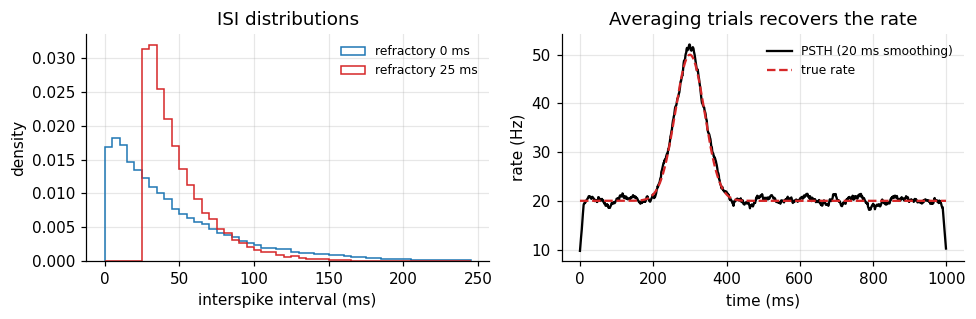

In [6]:
rate, T_s, n_trials = 20.0, 1.0, 2000                             # Hz, s, trials
dt_s = 1e-3
bins = int(T_s / dt_s)


def poisson_trains(rate, refractory_ms=0.0):
    spk = rng.random((n_trials, bins)) < rate * dt_s              # (trials, bins)
    if refractory_ms > 0:                                         # delete spikes inside the dead time
        dead = int(refractory_ms / 1000 / dt_s)
        for tr in range(n_trials):
            idx = np.flatnonzero(spk[tr]); last = -10**9
            for i in idx:
                if i - last <= dead:
                    spk[tr, i] = False
                else:
                    last = i
    return spk


fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for refr, col in [(0, "C0"), (25, "C3")]:
    spk = poisson_trains(rate if refr == 0 else rate / (1 - rate * refr / 1000), refr)
    counts = spk.sum(axis=1)                                      # (trials,)
    isi = np.concatenate([np.diff(np.flatnonzero(s)) for s in spk]) * dt_s * 1000   # ms
    fano = counts.var() / counts.mean()
    cv = isi.std() / isi.mean()
    print(f"refractory {refr:2d} ms: mean count {counts.mean():.1f}, Fano {fano:.2f}, ISI CV {cv:.2f}")
    axes[0].hist(isi, bins=np.arange(0, 250, 5), density=True, histtype="step", color=col, lw=1.5,
                 label=f"refractory {refr} ms")
axes[0].set(xlabel="interspike interval (ms)", ylabel="density", title="ISI distributions")
axes[0].legend(frameon=False, fontsize=8)

# A PSTH: average many trials of a time-varying rate
r_t = 20 + 30 * np.exp(-0.5 * ((np.arange(bins) - 300) / 40) ** 2)   # (bins,) Hz
spk = rng.random((n_trials, bins)) < r_t * dt_s
psth = spk.mean(axis=0) / dt_s                                    # (bins,) Hz
axes[1].plot(np.arange(bins), np.convolve(psth, np.ones(20) / 20, "same"), color="k", label="PSTH (20 ms smoothing)")
axes[1].plot(np.arange(bins), r_t, color="C3", ls="--", label="true rate")
axes[1].set(xlabel="time (ms)", ylabel="rate (Hz)", title="Averaging trials recovers the rate")
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

The pure Poisson train has Fano factor and CV near 1. A 25 ms dead time pulls both down. The
peristimulus time histogram (PSTH) shows the other use of averaging: the rate that a single trial
hides becomes visible over many.

The Poisson description is a **rate code**: only the expected number of spikes in a window
matters. Section 4 showed that real spike *times* can be precise. Which description is right
depends on the input and on the reader downstream, and the next section makes that concrete.

## 6. Integrator or coincidence detector?

Give a neuron two input pulses separated by a delay $\Delta$. Each pulse raises the voltage by
$A$, which then decays with $\tau$. The peak after the second pulse is

$$\mu_\text{peak} - \mu_0 = A\left(1 + e^{-\Delta/\tau}\right).$$

If one pulse alone stays below threshold but two simultaneous pulses cross it, the neuron fires
only when $\Delta$ is small enough: $\Delta < \tau \ln \frac{A}{(\theta - \mu_0) - A}$.
The size of that window is set by $\tau$.

- A **long** $\tau$ makes an **integrator**: inputs far apart in time still add up.
- A **short** $\tau$ makes a **coincidence detector**: only nearly simultaneous inputs count.

(König, Engel & Singer, 1996.) Cortical neurons in vivo sit between the two. Strong balanced
excitation and inhibition shortens their effective time constant (Shadlen & Newsome, 1998).

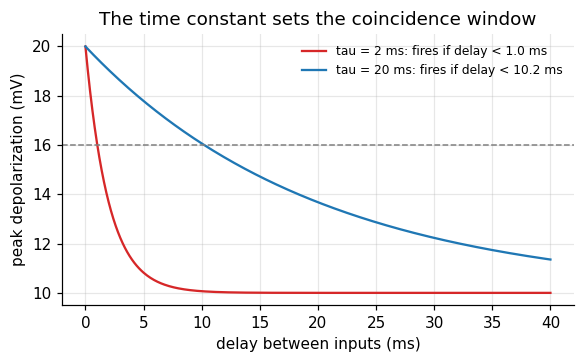

In [7]:
A = 10.0                                                          # mV per input pulse; threshold is 16 mV above rest
delays = np.linspace(0, 40, 401)                                  # (D,) ms between the two pulses
fig, ax = plt.subplots(figsize=(6, 3.2))
for tau_k, col in [(2.0, "C3"), (20.0, "C0")]:
    peak = A * (1 + np.exp(-delays / tau_k))                      # (D,) depolarization after pulse 2
    window = tau_k * np.log(A / ((theta - mu0) - A))
    ax.plot(delays, peak, color=col, label=f"tau = {tau_k:g} ms: fires if delay < {window:.1f} ms")
ax.axhline(theta - mu0, color="0.5", ls="--", lw=1)
ax.set(xlabel="delay between inputs (ms)", ylabel="peak depolarization (mV)",
       title="The time constant sets the coincidence window")
ax.legend(frameon=False, fontsize=8)
plt.show()

### What Part I gives us

- The LIF equation, solved by Euler steps and checked against the closed form.
- The f-I curve: a threshold, then a roughly linear rise.
- Below threshold, the neuron is a linear filter with an exponential memory of length $\tau$.
- Spike timing can be precise; irregular output may reflect irregular input.
- Poisson spikes have Fano factor and ISI CV near 1; refractoriness lowers both.
- The same time constant decides between integration and coincidence detection.

# Part II · Case study: can a single neuron tell time?

## Stage 1 · Cognitive phenomenon

Two timing abilities look unrelated.

- **Microseconds.** Barn owls turn their head toward a sound with an accuracy that requires
  telling apart interaural time differences (ITDs) of a few microseconds. Neurons in the owl's
  nucleus laminaris fire most for one particular ITD (Carr & Konishi, 1990).
- **Hundreds of milliseconds to seconds.** Humans and animals reproduce intervals with errors that
  grow in proportion to the interval: the scalar property, Weber's law for time (Gibbon, 1977).

The question: which of these can be explained by the time constant of a single neuron? Section 6
suggests an answer for the first. Section 3 suggests a problem for the second: a single neuron
forgets within a few $\tau$.

## Stage 2 · Behavioral experiment

We pose both problems to model neurons, the way an electrophysiologist would.

- **ITD experiment.** A 500 Hz tone reaches the two ears with a time difference. Each ear sends four
  input fibers, each firing on about half of the tone's cycles, locked to its phase with 60 μs of
  timing jitter. A detector neuron with a 200 μs time constant receives both ears, and the left
  input passes an internal axonal delay of 120 μs. We play
  25 ITDs between $-500$ and $+500$ μs and count its spikes.
- **Interval experiment.** A brief pulse starts the interval. At a later time $t$ we read out the
  neuron's state and ask how well $t$ can be recovered from it.

In [8]:
# ITD experiment: microsecond resolution needs a microsecond time step
dt_us = 5.0                                                       # μs
dur_us = 50_000                                                   # 50 ms of tone
t_us = np.arange(0, dur_us, dt_us)                                # (T,)
f_tone = 500.0                                                    # Hz
period_us = 1e6 / f_tone
jitter_us = 60.0
n_fibers = 4                                                      # input fibers per ear
true_delay = 120.0                                                # μs: internal delay on the left input
itds = np.linspace(-500, 500, 25)                                 # (n_itd,) μs, positive = left ear later


def ear_spikes(offset_us, n):
    # One fiber: a spike per cycle with probability 0.5, at the tone's phase plus jitter. (n, T) bool.
    cycles = np.arange(0, dur_us, period_us)
    S = np.zeros((n, t_us.size), bool)
    for i in range(n):
        keep = rng.random(cycles.size) < 0.5
        times = cycles[keep] + offset_us + rng.normal(0, jitter_us, keep.sum())
        idx = np.round(times / dt_us).astype(int)
        S[i, idx[(idx >= 0) & (idx < t_us.size)]] = True
    return S


def detector_counts(itd_list, n_rep, tau_us=200.0, w=5.0, thr=14.0):
    # Coincidence detector: leaky sum of both ears' input, spike above thr, reset to 0.
    counts = np.zeros((len(itd_list), n_rep))
    for a, itd in enumerate(itd_list):
        left = sum(ear_spikes(itd + true_delay, n_rep).astype(float) for _ in range(n_fibers))
        right = sum(ear_spikes(0.0, n_rep).astype(float) for _ in range(n_fibers))
        drive = (left + right) * w                                # (n_rep, T) mV jumps
        v = np.zeros(n_rep); c = np.zeros(n_rep)
        decay = np.exp(-dt_us / tau_us)
        for k in range(t_us.size):
            v = v * decay + drive[:, k]
            fired = v >= thr
            c += fired; v[fired] = 0.0
        counts[a] = c
    return counts                                                 # (n_itd, n_rep)


itd_counts = detector_counts(itds, n_rep=10)
print("spike counts:", itd_counts.shape, " mean per ITD:", itd_counts.mean(axis=1).round(1)[::4])

spike counts: (25, 10)  mean per ITD: [ 6.   8.2 14.5 11.4  5.5  4.3  3.3]


## Stage 3 · Empirical signature

For the ITD experiment, the signature is a **tuning curve**: spike count against ITD. For the
interval experiment, it is **timing error against elapsed time**. We look at the first now and
the second after building the model.

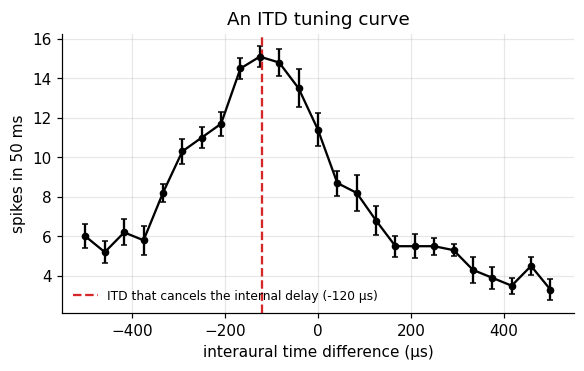

In [9]:
mean_c = itd_counts.mean(axis=1); se_c = itd_counts.std(axis=1) / np.sqrt(itd_counts.shape[1])
fig, ax = plt.subplots(figsize=(6, 3.3))
ax.errorbar(itds, mean_c, yerr=se_c, fmt="o-", color="k", capsize=2, ms=4)
ax.axvline(-true_delay, color="C3", ls="--", label=f"ITD that cancels the internal delay ({-true_delay:g} μs)")
ax.set(xlabel="interaural time difference (μs)", ylabel="spikes in 50 ms", title="An ITD tuning curve")
ax.legend(frameon=False, fontsize=8)
plt.show()

The detector fires most when the ITD cancels its internal delay: then the two ears' spikes arrive
together. This is Jeffress's (1948) proposal: a row of detectors with different internal delays
turns a *time* difference into a *place* in the row, which is also a place in auditory space.

## Stage 4 · Computational model

### Coincidence: recovering the preferred ITD

The detector computes something like a product of its two inputs over a short window. Near its
peak, the tuning curve is well described by a baseline plus a bump centered on the ITD that
cancels the internal delay:

$$c(\text{ITD}) = b + g\,\exp\!\left(-\frac{(\text{ITD} - \text{ITD}^*)^2}{2w^2}\right).$$

| symbol | meaning |
|---|---|
| $b$ | firing from chance coincidences |
| $g$ | extra firing when the ears line up |
| $\text{ITD}^*$ | preferred ITD: minus the internal delay |
| $w$ | tuning width, set by input jitter and the time constant |

Can we recover $\text{ITD}^*$ from spike counts? Parameter recovery: fit the curve to many small
simulated experiments and look at the spread of the estimates.

In [10]:
def tuning(itd, b, g, itd_star, w):
    return b + g * np.exp(-0.5 * ((itd - itd_star) / w) ** 2)


p, _ = curve_fit(tuning, np.repeat(itds, itd_counts.shape[1]), itd_counts.ravel(), p0=[3, 8, 0, 200])
print(f"estimated preferred ITD {p[2]:.1f} μs (truth {-true_delay:.1f} μs), width {abs(p[3]):.0f} μs")

est = []
for rep in range(8):
    c_rep = detector_counts(itds, n_rep=3)                        # small experiments: 3 tones per ITD
    pp, _ = curve_fit(tuning, np.repeat(itds, 3), c_rep.ravel(), p0=[3, 8, 0, 200])
    est.append(pp[2])
est = np.array(est)
print(f"8 small experiments: mean {est.mean():.1f} μs, SD {est.std():.1f} μs")

estimated preferred ITD -122.8 μs (truth -120.0 μs), width 143 μs


8 small experiments: mean -111.3 μs, SD 10.8 μs


With only three 50 ms tones per ITD, the preferred ITD is recovered to about ten microseconds,
with a small bias toward zero that comes from fitting a symmetric bump to a curve that is not
perfectly symmetric. The input jitter is 60 μs and the time constant is 200 μs, yet the averaged
coincidences resolve much finer differences. A single neuron with a short time constant can
compare arrival times at microsecond scale.

### Elapsed time: what a decaying trace can tell

Now the second problem. After a pulse at time 0, the neuron's state decays:
$x(t) = A e^{-t/\tau}$. A reader sees $x$ plus noise of size $\sigma$ and must infer $t$. Invert the
decay: $\hat t = -\tau \ln(x/A)$. A small error $\delta x$ in $x$ becomes an error in time of
$\delta t = \delta x / |dx/dt|$, so

$$\mathrm{SD}(\hat t) \approx \frac{\sigma}{|dx/dt|} = \frac{\sigma\,\tau}{A}\, e^{t/\tau}.$$

The error grows **exponentially** with elapsed time. Check by simulation:

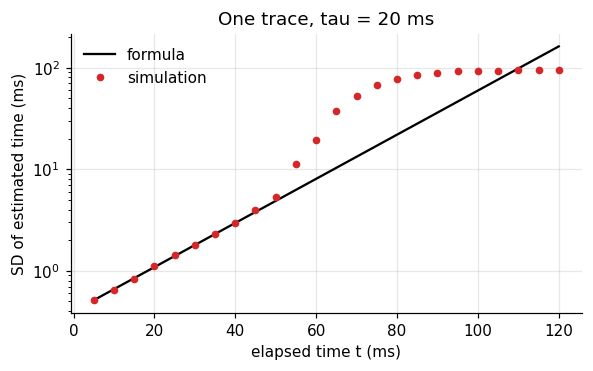

SD at 20, 60, 100 ms: [ 1.1 19.4 92.9] ms


In [11]:
A_tr, sigma_tr = 1.0, 0.02                                        # trace amplitude, readout noise
t_probe = np.linspace(5, 120, 24)                                 # (P,) ms
n_sim = 4000
x_obs = A_tr * np.exp(-t_probe[:, None] / tau) + sigma_tr * rng.normal(size=(t_probe.size, n_sim))   # (P, n)
t_hat = -tau * np.log(np.clip(x_obs, 1e-6, None) / A_tr)          # (P, n)
sd_sim = t_hat.std(axis=1)                                        # (P,)
sd_formula = sigma_tr * tau / A_tr * np.exp(t_probe / tau)        # (P,)

fig, ax = plt.subplots(figsize=(6, 3.3))
ax.plot(t_probe, sd_formula, color="k", label="formula")
ax.plot(t_probe, sd_sim, "o", color="C3", ms=4, label="simulation")
ax.set(xlabel="elapsed time t (ms)", ylabel="SD of estimated time (ms)", yscale="log",
       title=f"One trace, tau = {tau:g} ms")
ax.legend(frameon=False)
plt.show()
print("SD at 20, 60, 100 ms:", np.interp([20, 60, 100], t_probe, sd_sim).round(1), "ms")

Simulation and formula agree until the trace sinks into the noise; then the estimate saturates
because the information is simply gone. For a 20 ms membrane, elapsed time is readable for a few
tens of milliseconds. Even a slow synaptic process with $\tau = 100$ ms only moves the cliff.

| claim | status |
|---|---|
| A single neuron can compare arrival times at microsecond scale. | **consistent with** the owl data and **implementable** (this simulation) |
| A single decaying trace can time intervals of a second. | rejected by the formula: the error grows as $e^{t/\tau}$ |

## Stage 5 · Neural implementation

If one time constant is not enough, use many. Suppose a pulse starts decaying traces in a bank of
neurons whose time constants are spread on a logarithmic scale, from 10 ms to 5 s. Each trace is
best at reading time near its own $\tau$, where its slope is steepest relative to its size. A
reader that combines all of them (maximum likelihood on a grid of candidate times) has a good
trace available at every scale.

The same idea appears in theories of a scale invariant internal timeline (Shankar & Howard, 2012).
Here we only ask what such a bank predicts for timing error.

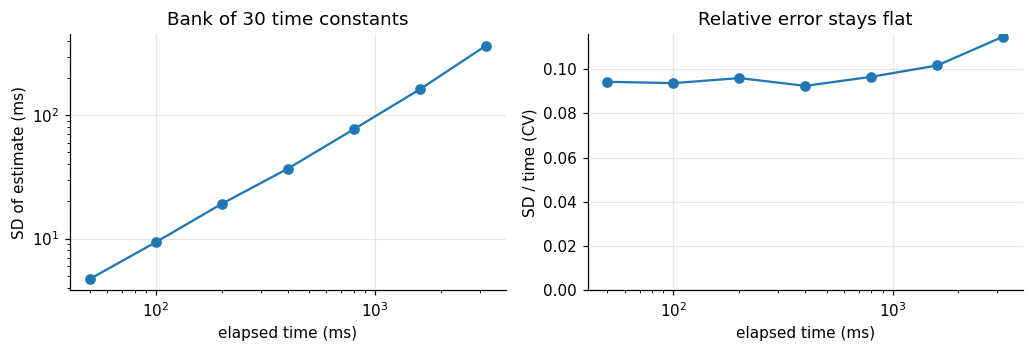

CV per elapsed time: [0.094 0.094 0.096 0.092 0.096 0.102 0.115]


In [12]:
taus = np.exp(np.linspace(np.log(10), np.log(5000), 30))         # (J,) ms, log spaced
t_cand = np.linspace(1, 6000, 3000)                               # (G,) candidate times
traces = np.exp(-t_cand[:, None] / taus[None, :])                 # (G, J) noiseless bank state
sigma_bank = 0.1                                                  # readout noise per trace
t_test = np.array([50, 100, 200, 400, 800, 1600, 3200])           # (P,) ms
sd_bank = []
for tt in t_test:
    x = np.exp(-tt / taus)[None, :] + sigma_bank * rng.normal(size=(1000, taus.size))   # (n, J)
    sq = ((x[:, None, :] - traces[None, :, :]) ** 2).sum(axis=2)  # (n, G) squared distance per candidate
    est_t = t_cand[sq.argmin(axis=1)]                              # (n,) maximum likelihood estimate
    sd_bank.append(est_t.std())
sd_bank = np.array(sd_bank)
cv = sd_bank / t_test

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.3))
axes[0].plot(t_test, sd_bank, "o-", color="C0")
axes[0].set(xlabel="elapsed time (ms)", ylabel="SD of estimate (ms)", xscale="log", yscale="log",
            title="Bank of 30 time constants")
axes[1].plot(t_test, cv, "o-", color="C0")
axes[1].set(xlabel="elapsed time (ms)", ylabel="SD / time (CV)", xscale="log", ylim=(0, None),
            title="Relative error stays flat")
plt.tight_layout()
plt.show()
print("CV per elapsed time:", cv.round(3))

The bank's error grows in proportion to the elapsed time: the CV stays nearly constant across a
range of almost two orders of magnitude. That is Weber's law, and it falls out of nothing more
than log spaced time constants. A single trace gave exponential growth; a log spaced bank gives
linear growth.

This is an **implementable** account, not evidence that the brain uses it. Neurons with time
constants of seconds are rare, so a real bank would need slow network or cellular mechanisms. Later
tutorials return to how networks produce slow dynamics.

## Stage 6 · Prediction and failure

| prediction | test | rejected if |
|---|---|---|
| ITD tuning is periodic at the tone's period and peaks where internal and external delays cancel. | tuning curves at several tone frequencies | the peak ITD shifts with frequency in a way delays cannot explain |
| Shorter membrane time constants give sharper coincidence windows. | compare neurons or conditions with different $\tau$ | tuning width is unrelated to $\tau$ |
| One decaying trace cannot time seconds; errors would explode beyond a few $\tau$. | timing error at long intervals | behavior is scalar far beyond any single $\tau$ (it is) |
| A log spaced bank gives a flat CV up to its longest $\tau$, then breaks down. | timing beyond the slowest available process | CV stays flat however long the interval |

The last row is the useful one: the bank model must fail somewhere. Below we push the interval past
the slowest time constant and look for the break.

CV at [ 1000  2000  4000  8000 16000] ms: [0.095 0.1   0.129 0.469 0.804]


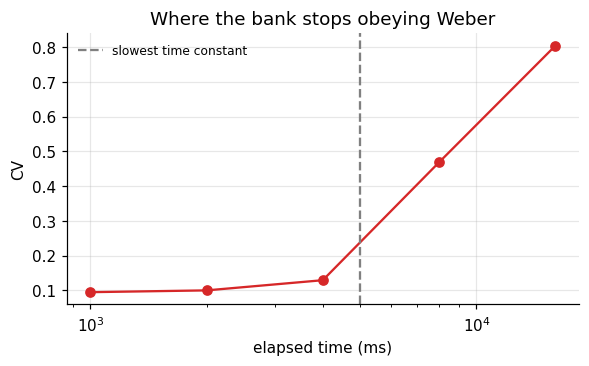

In [13]:
t_far = np.array([1000, 2000, 4000, 8000, 16000])                 # ms, beyond the 5 s maximum tau
t_cand_far = np.linspace(1, 40000, 8000)
traces_far = np.exp(-t_cand_far[:, None] / taus[None, :])         # (G, J)
cv_far = []
for tt in t_far:
    x = np.exp(-tt / taus)[None, :] + sigma_bank * rng.normal(size=(500, taus.size))
    sq = ((x[:, None, :] - traces_far[None, :, :]) ** 2).sum(axis=2)
    cv_far.append(t_cand_far[sq.argmin(axis=1)].std() / tt)
print("CV at", t_far, "ms:", np.round(cv_far, 3))

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(t_far, cv_far, "o-", color="C3")
ax.axvline(taus.max(), color="0.5", ls="--", label="slowest time constant")
ax.set(xlabel="elapsed time (ms)", ylabel="CV", xscale="log", title="Where the bank stops obeying Weber")
ax.legend(frameon=False, fontsize=8)
plt.show()

As the interval approaches and passes the slowest time constant (5 s), the CV climbs from about
0.1 to several times that: the bank has no trace left that still changes, so it loses track. This is a concrete, falsifiable claim. If human timing stayed scalar for intervals
far beyond any plausible slow process in the brain, a fixed bank of decays would be the wrong
model, and timing would need a mechanism that does not forget, such as an accumulator (Foundations
16) or a network that keeps moving (later tutorials).

## What to carry forward

- The LIF neuron is a leaky integrator: $\tau\dot\mu = -(\mu - \mu_0) + RI$, plus threshold and reset.
- Below threshold it is a linear filter with exponential memory $e^{-u/\tau}$.
- Spike timing can be precise; irregular output can reflect irregular input.
- Poisson trains have Fano factor and CV near 1; refractoriness lowers both.
- Short $\tau$ detects coincidences; long $\tau$ integrates. One number decides.
- One neuron can compare arrival times to microseconds, but cannot hold elapsed time beyond a few
  $\tau$: its timing error grows as $e^{t/\tau}$.
- A log spaced bank of time constants gives Weber's law, and predicts where Weber's law must fail.

## References

- Carr, C. E., & Konishi, M. (1990). A circuit for detection of interaural time differences in the
  brain stem of the barn owl. *Journal of Neuroscience*, 10(10), 3227 to 3246.
- Gibbon, J. (1977). Scalar expectancy theory and Weber's law in animal timing. *Psychological
  Review*, 84(3), 279 to 325.
- Jeffress, L. A. (1948). A place theory of sound localization. *Journal of Comparative and
  Physiological Psychology*, 41(1), 35 to 39.
- König, P., Engel, A. K., & Singer, W. (1996). Integrator or coincidence detector? The role of the
  cortical neuron revisited. *Trends in Neurosciences*, 19(4), 130 to 137.
- Lapicque, L. (1907). Recherches quantitatives sur l'excitation électrique des nerfs traitée comme
  une polarisation. *Journal de Physiologie et de Pathologie Générale*, 9, 620 to 635.
- Mainen, Z. F., & Sejnowski, T. J. (1995). Reliability of spike timing in neocortical neurons.
  *Science*, 268(5216), 1503 to 1506.
- Shadlen, M. N., & Newsome, W. T. (1998). The variable discharge of cortical neurons: implications
  for connectivity, computation, and information coding. *Journal of Neuroscience*, 18(10), 3870
  to 3896.
- Shankar, K. H., & Howard, M. W. (2012). A scale-invariant internal representation of time.
  *Neural Computation*, 24(1), 134 to 193.
- Softky, W. R., & Koch, C. (1993). The highly irregular firing of cortical cells is inconsistent
  with temporal integration of random EPSPs. *Journal of Neuroscience*, 13(1), 334 to 350.
- Tolhurst, D. J., Movshon, J. A., & Dean, A. F. (1983). The statistical reliability of signals in
  single neurons in cat and monkey visual cortex. *Vision Research*, 23(8), 775 to 785.